In [1]:
import pandas as pd
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt

mpl.rcParams['font.size'] = 14
mpl.rcParams['font.family'] = 'Arial'

colors = [
    '#8686D2',
    '#7BAED3',
    '#9CCBA0',
    '#E6DC84',
    '#D47291',
    '#868686',
]

In [2]:
as7341_data_path = '../data/as7341/as7341_spectral_response.csv'
df_pd = pd.read_csv(as7341_data_path)

wavelengths_pd = df_pd['wavelength']
sensitivities = df_pd.drop(columns=['wavelength'])

led_data_path = '../data/as7341/cree_xd16_4500K_interp.csv'
df_led = pd.read_csv(led_data_path)

wavelengths_led = df_led['wavelength']
intensities = df_led['intensity']

In [3]:
hb_data_path = '../data/as7341/hb_hbo2.csv'
df_hb = pd.read_csv(hb_data_path)

wavelengths_hb = df_hb['wavelength']
hb = df_hb['Hb']
hbo2 = df_hb['HbO2']

hb_log = hb.apply(lambda x: np.log(x))
hbo2_log = hbo2.apply(lambda x: np.log(x))

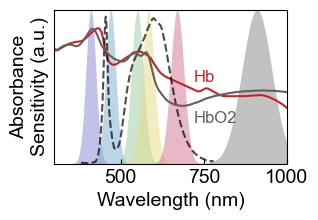

In [4]:
plt.figure(figsize=(3, 2))

plt.plot(wavelengths_hb, hb_log, label='Hb', color='#cb222a')
plt.plot(wavelengths_led, intensities * 20, label='LED Intensity', color='#000000', linestyle='--', alpha=0.7)
plt.plot(wavelengths_hb, hbo2_log, label='HbO2', color='#655e5c')
for i, (column, color) in enumerate(zip(sensitivities.columns, colors)):
    plt.fill_between(wavelengths_pd, 0, sensitivities[column] * 15, 
                     color=colors[i], alpha=0.5, lw=0)
plt.text(720, 8, 'Hb', color='#cb222a', fontsize=12)
plt.text(720, 4, 'HbO2', color='#655e5c', fontsize=12)
plt.xlim(300, 1000)
plt.ylim(0, 15)

plt.xlabel('Wavelength (nm)')
plt.ylabel('Absorbance\nSensitivity (a.u.)')

plt.yticks([])
plt.tick_params(direction='in')

# plt.savefig('../figures/fig1/sensor_spectra_vs_chromophore.png', dpi=600, bbox_inches='tight', transparent=True)
plt.show()